<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/code/01NAEX_Ex04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 04: Latin squares, Graeco-Latin squares and balanced incomplete block designs

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 4.
Problem numbers follow the 8th edition. This is a short exercise: the assignment of the week is **Team Project 1**.

## Learning goals

* Analyse a Latin square and a Graeco-Latin square in `statsmodels` and compare treatments with the correct error mean square.
* Analyse a balanced incomplete block design (BIBD): treatments adjusted for blocks, adjusted means, Tukey's test.
* See why the order of terms matters in a sequential ANOVA of a non-orthogonal design.
* Randomize a Latin square and prepare a randomized run sheet for a blocked factorial experiment (Team Project 1).

## Setup

Run this cell first. Besides the standard imports it defines helper functions used below:

* `tukey_from_model()` - Tukey's HSD with $MS_E$ and $df_E$ of a fitted model (from Exercise 03; balanced designs only).
* `bibd_analysis()` - intrablock analysis of a BIBD: $Q_i$, adjusted treatment effects $\hat\tau_i = kQ_i/(\lambda a)$,
  adjusted means and Tukey's test based on them.
* `random_latin_square()` - a randomized $p \times p$ Latin square.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def tukey_from_model(model, data, factor, response, alpha=0.05):
    """Tukey's HSD for the levels of `factor`, using MS_E and df_E of a fitted model (balanced data)."""
    mse, dfe = model.mse_resid, model.df_resid
    means = data.groupby(factor, observed=True)[response].mean()
    n = data.groupby(factor, observed=True)[response].count().iloc[0]
    k = len(means)
    se = np.sqrt(mse / n)
    hsd = stats.studentized_range.ppf(1 - alpha, k, dfe) * se
    rows = []
    levels = list(means.index)
    for i in range(k):
        for j in range(i + 1, k):
            diff = means.iloc[j] - means.iloc[i]
            rows.append({"pair": f"{levels[j]} - {levels[i]}", "diff": diff,
                         "lower": diff - hsd, "upper": diff + hsd,
                         "p_adj": stats.studentized_range.sf(abs(diff) / se, k, dfe),
                         "reject": abs(diff) > hsd})
    print(f"MS_E = {mse:.4g}, df_E = {dfe:.0f}, n per level = {n}, HSD = {hsd:.4g}")
    return pd.DataFrame(rows)


def bibd_analysis(data, response, treatment, block, alpha=0.05):
    """Intrablock analysis of a balanced incomplete block design.

    Returns the fitted model, a table with Q_i, the adjusted effects and adjusted means, and Tukey's pairwise comparisons
    of the adjusted means (Var(tau_i - tau_j) = 2 k sigma^2 / (lambda a)).
    """
    model = smf.ols(f"{response} ~ C({block}) + C({treatment})", data=data).fit()
    a, b = data[treatment].nunique(), data[block].nunique()
    k = data.groupby(block).size().iloc[0]
    r = data.groupby(treatment).size().iloc[0]
    lam = r * (k - 1) / (a - 1)
    y_trt = data.groupby(treatment)[response].sum()
    y_blk = data.groupby(block)[response].sum()
    Q = pd.Series({t: y_trt[t] - y_blk[d[block]].sum() / k for t, d in data.groupby(treatment)})
    tau = k * Q / (lam * a)
    table = pd.DataFrame({"Q": Q, "tau_adj": tau, "mean_adj": data[response].mean() + tau,
                          "mean_raw": data.groupby(treatment)[response].mean()})
    se = np.sqrt(k * model.mse_resid / (lam * a))
    hsd = stats.studentized_range.ppf(1 - alpha, a, model.df_resid) * se
    rows = []
    levels = list(tau.index)
    for i in range(a):
        for j in range(i + 1, a):
            diff = tau.iloc[j] - tau.iloc[i]
            rows.append({"pair": f"{levels[j]} - {levels[i]}", "diff": diff,
                         "lower": diff - hsd, "upper": diff + hsd,
                         "p_adj": stats.studentized_range.sf(abs(diff) / se, a, model.df_resid),
                         "reject": abs(diff) > hsd})
    print(f"a = {a}, b = {b}, k = {k}, r = {r}, lambda = {lam:g}; MS_E = {model.mse_resid:.4g}, "
          f"df_E = {model.df_resid:.0f}, HSD = {hsd:.4g}")
    return model, table, pd.DataFrame(rows)


def random_latin_square(p, seed=None, symbols="ABCDEFGHIJ"):
    """Randomized p x p Latin square: a cyclic square with randomly permuted rows, columns and symbols."""
    rng = np.random.default_rng(seed)
    square = np.add.outer(np.arange(p), np.arange(p)) % p
    square = square[rng.permutation(p)][:, rng.permutation(p)]
    letters = np.array(list(symbols[:p]))[rng.permutation(p)]
    return pd.DataFrame(letters[square], index=[f"row {i + 1}" for i in range(p)],
                        columns=[f"col {j + 1}" for j in range(p)])

## 1. Lecture example: rocket propellant (Latin square)

Montgomery, Example 4.3: five formulations of a rocket propellant (A-E) are compared by their burning rate. Each batch of
raw material is large enough for five formulations, and the formulations are prepared by five operators. Batches (rows)
and operators (columns) are two nuisance factors; each formulation appears once in every batch and once with every operator.

In [2]:
rocket = pd.read_csv(URL + "rocket.txt", sep=r"\s+")
print("Design (formulation in each batch x operator cell):")
display(rocket.pivot(index="batch", columns="op", values="treat"))
print("Burning rate:")
display(rocket.pivot(index="batch", columns="op", values="y"))

Design (formulation in each batch x operator cell):


op,1,2,3,4,5
batch,,,,,
1,A,B,C,D,E
2,B,C,D,E,A
3,C,D,E,A,B
4,D,E,A,B,C
5,E,A,B,C,D


Burning rate:


op,1,2,3,4,5
batch,,,,,
1,24,20,19,24,24
2,17,24,30,27,36
3,18,38,26,27,21
4,26,31,26,23,22
5,22,30,20,29,31


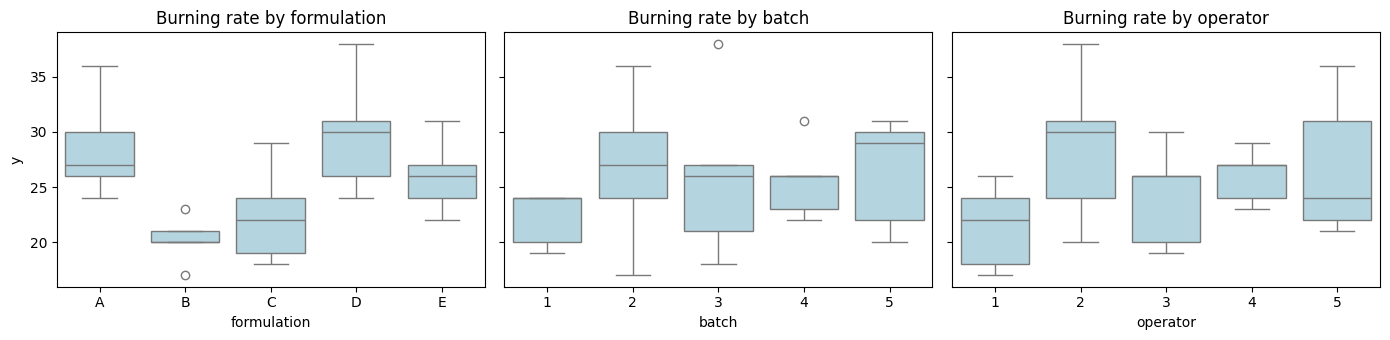

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, factor, title in zip(axes, ["treat", "batch", "op"], ["formulation", "batch", "operator"]):
    sns.boxplot(data=rocket, x=factor, y="y", ax=ax, color="lightblue")
    ax.set(xlabel=title, title=f"Burning rate by {title}")
plt.tight_layout(); plt.show()

In [4]:
ls = smf.ols("y ~ C(batch) + C(op) + C(treat)", data=rocket).fit()
display(sm.stats.anova_lm(ls, typ=2))

# the same data without the batch blocks (an RCBD with operators as blocks)
ls_nobatch = smf.ols("y ~ C(op) + C(treat)", data=rocket).fit()
display(sm.stats.anova_lm(ls_nobatch, typ=2))
print(f"MS_E Latin square = {ls.mse_resid:.2f} ({ls.df_resid:.0f} df), without batches = {ls_nobatch.mse_resid:.2f} ({ls_nobatch.df_resid:.0f} df)")

,sum_sq,df,F,PR(>F)
C(batch),68.0,4.0,1.593750,0.239059
C(op),150.0,4.0,3.515625,0.040373
C(treat),330.0,4.0,7.734375,0.002537
Residual,128.0,12.0,NaN,NaN


,sum_sq,df,F,PR(>F)
C(op),150.0,4.0,3.061224,0.047378
C(treat),330.0,4.0,6.734694,0.002237
Residual,196.0,16.0,NaN,NaN


MS_E Latin square = 10.67 (12 df), without batches = 12.25 (16 df)


The formulations differ ($F_0 = 7.73$, $p = 0.0025$), operators differ somewhat ($p = 0.040$), and there is no strong evidence
of a batch effect ($p = 0.24$). Blocking on batches cost 4 error degrees of freedom and reduced $MS_E$ only from 12.25 to 10.67;
we could not know that before the experiment.

### Which formulations differ? Model adequacy

MS_E = 10.67, df_E = 12, n per level = 5, HSD = 6.584


,pair,diff,lower,upper,p_adj,reject
0,B - A,-8.4,-14.9839,-1.8161,0.0111,True
1,C - A,-6.2,-12.7839,0.3839,0.0684,False
2,D - A,1.2,-5.3839,7.7839,0.9754,False
3,E - A,-2.6,-9.1839,3.9839,0.7194,False
4,C - B,2.2,-4.3839,8.7839,0.8205,False
5,D - B,9.6,3.0161,16.1839,0.0042,True
6,E - B,5.8,-0.7839,12.3839,0.0944,False
7,D - C,7.4,0.8161,13.9839,0.0254,True
8,E - C,3.6,-2.9839,10.1839,0.4462,False
9,E - D,-3.8,-10.3839,2.7839,0.3967,False


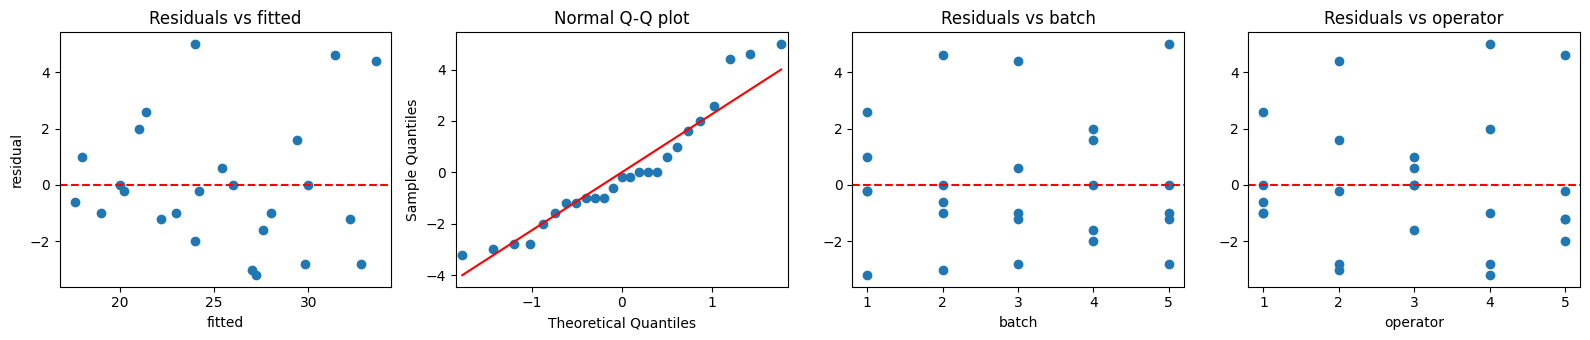

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9223949983744741), pvalue=np.float64(0.0581058294695291))


In [5]:
display(tukey_from_model(ls, rocket, "treat", "y").round(4))

res, fit = ls.resid, ls.fittedvalues
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].scatter(fit, res); axes[0].axhline(0, color="red", ls="--"); axes[0].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
sm.qqplot(res, line="s", ax=axes[1]); axes[1].set_title("Normal Q-Q plot")
axes[2].scatter(rocket["batch"], res); axes[2].axhline(0, color="red", ls="--"); axes[2].set(xlabel="batch", title="Residuals vs batch")
axes[3].scatter(rocket["op"], res); axes[3].axhline(0, color="red", ls="--"); axes[3].set(xlabel="operator", title="Residuals vs operator")
plt.tight_layout(); plt.show()
print("Shapiro-Wilk on residuals:", stats.shapiro(res))

Formulations D and A give a higher burning rate than B, and D also higher than C; the other differences are not significant
(HSD = 6.58). The residuals show no clear pattern; the Shapiro-Wilk test is borderline ($p = 0.058$), which is not unusual for
integer data with 12 error degrees of freedom.

## 2. Lecture example: Graeco-Latin square (test assemblies)

Montgomery, Example 4.4: the five test assemblies $\alpha, \dots, \varepsilon$ are a third nuisance factor. In Montgomery's
Table 4.20 the assembly used in batch $i$ and operator $j$ is the Greek letter number $(i + 2j) \bmod 5$ (zero-based indices).

In [6]:
greek = ["alpha", "beta", "gamma", "delta", "epsilon"]
rocket["assembly"] = [greek[(b - 1 + 2 * (o - 1)) % 5] for b, o in zip(rocket["batch"], rocket["op"])]
display(rocket.assign(cell=rocket["treat"] + " " + rocket["assembly"]).pivot(index="batch", columns="op", values="cell"))

# every Latin letter appears exactly once with every Greek letter
print(pd.crosstab(rocket["treat"], rocket["assembly"]))

gl = smf.ols("y ~ C(batch) + C(op) + C(treat) + C(assembly)", data=rocket).fit()
display(sm.stats.anova_lm(gl, typ=2))

op,1,2,3,4,5
batch,,,,,
1,A alpha,B gamma,C epsilon,D beta,E delta
2,B beta,C delta,D alpha,E gamma,A epsilon
3,C gamma,D epsilon,E beta,A delta,B alpha
4,D delta,E alpha,A gamma,B epsilon,C beta
5,E epsilon,A beta,B delta,C alpha,D gamma


assembly  alpha  beta  delta  epsilon  gamma
treat                                       
A             1     1      1        1      1
B             1     1      1        1      1
C             1     1      1        1      1
D             1     1      1        1      1
E             1     1      1        1      1


,sum_sq,df,F,PR(>F)
C(batch),68.0,4.0,2.060606,0.178311
C(op),150.0,4.0,4.545455,0.032930
C(treat),330.0,4.0,10.000000,0.003344
C(assembly),62.0,4.0,1.878788,0.207641
Residual,66.0,8.0,NaN,NaN


Removing the assembly variability ($SS = 62$) reduces $MS_E$ from 10.67 to 8.25, but the error degrees of freedom drop from
12 to 8. The formulations are still clearly different ($F_0 = 10.0$, $p = 0.003$); assemblies are not significant.

## 3. Lecture example: catalyst experiment (BIBD)

Montgomery, Example 4.5: four catalysts, batches of raw material as blocks, but each batch is large enough for three catalysts
only. $a = 4$, $b = 4$, $k = 3$, $r = 3$, $\lambda = 2$.

In [7]:
cat = pd.DataFrame({"block": [1, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 4],
                    "catalyst": [1, 3, 4, 1, 2, 3, 2, 3, 4, 1, 2, 4],
                    "time": [73, 73, 75, 74, 75, 75, 67, 68, 72, 71, 72, 75]})
display(cat.pivot(index="catalyst", columns="block", values="time"))

# balance check: how many times does each pair of catalysts share a block?
incidence = pd.crosstab(cat["catalyst"], cat["block"])
print("lambda matrix (off-diagonal = number of blocks shared by a pair):")
print(incidence @ incidence.T)

block,1,2,3,4
catalyst,,,,
1,73.0,74.0,NaN,71.0
2,NaN,75.0,67.0,72.0
3,73.0,75.0,68.0,NaN
4,75.0,NaN,72.0,75.0


lambda matrix (off-diagonal = number of blocks shared by a pair):
catalyst  1  2  3  4
catalyst            
1         3  2  2  2
2         2  3  2  2
3         2  2  3  2
4         2  2  2  3


In [8]:
print("Blocks first: treatments adjusted for blocks (the correct test)")
display(sm.stats.anova_lm(smf.ols("time ~ C(block) + C(catalyst)", data=cat).fit(), typ=1))
print("Catalysts first: unadjusted treatment SS, blocks adjusted for treatments")
display(sm.stats.anova_lm(smf.ols("time ~ C(catalyst) + C(block)", data=cat).fit(), typ=1))

Blocks first: treatments adjusted for blocks (the correct test)


,df,sum_sq,mean_sq,F,PR(>F)
C(block),3.0,55.00,18.333333,28.205128,0.001468
C(catalyst),3.0,22.75,7.583333,11.666667,0.010739
Residual,5.0,3.25,0.650000,NaN,NaN


Catalysts first: unadjusted treatment SS, blocks adjusted for treatments


,df,sum_sq,mean_sq,F,PR(>F)
C(catalyst),3.0,11.666667,3.888889,5.982906,0.041463
C(block),3.0,66.083333,22.027778,33.888889,0.000953
Residual,5.0,3.250000,0.650000,NaN,NaN


In [9]:
bibd, adj, tukey_cat = bibd_analysis(cat, "time", "catalyst", "block")
display(adj.round(4))
display(tukey_cat.round(4))

a = 4, b = 4, k = 3, r = 3, lambda = 2; MS_E = 0.65, df_E = 5, HSD = 2.576


,Q,tau_adj,mean_adj,mean_raw
1,-3.0000,-1.125,71.375,72.6667
2,-2.3333,-0.875,71.625,71.3333
3,-1.3333,-0.500,72.000,72.0000
4,6.6667,2.500,75.000,74.0000


,pair,diff,lower,upper,p_adj,reject
0,2 - 1,0.250,-2.3263,2.8263,0.9825,False
1,3 - 1,0.625,-1.9513,3.2013,0.8085,False
2,4 - 1,3.625,1.0487,6.2013,0.0130,True
3,3 - 2,0.375,-2.2013,2.9513,0.9462,False
4,4 - 2,3.375,0.7987,5.9513,0.0175,True
5,4 - 3,3.000,0.4237,5.5763,0.0281,True


The catalysts differ ($F_0 = 11.67$, $p = 0.011$, catalysts adjusted for blocks). The adjusted means are 71.375, 71.625, 72.0
and 75.0; catalyst 4 gives a longer reaction time than catalysts 1, 2 and 3, which do not differ (HSD = 2.58).
Note that the raw means differ from the adjusted ones because each catalyst misses a different batch.

## 4. Randomizing a design in Python

A randomized Latin square: start from a cyclic square and permute rows, columns and symbols at random. (For $p \ge 4$ this does not
reach every Latin square with equal probability, but it is the standard practical recipe.) Fix the seed so the plan can be reproduced.

In [10]:
random_latin_square(4, seed=2026)

,col 1,col 2,col 3,col 4
row 1,D,A,B,C
row 2,B,C,D,A
row 3,A,B,C,D
row 4,C,D,A,B


A randomized run sheet for a factorial experiment in blocks, as required in **Team Project 1**: every block (operator or
session) runs all $3 \times 3 \times 2 = 18$ combinations once, in its own random order. The levels below are only an example;
use your own. The sheet can be saved with `to_csv()` and printed for the lab.

In [11]:
levels = {"L_m": [0.30, 0.60, 1.00], "theta_deg": [10, 30, 50], "mass": ["light", "heavy"]}
combos = pd.MultiIndex.from_product(levels.values(), names=levels.keys()).to_frame(index=False)

rng = np.random.default_rng(2026)
blocks = []
for block in [1, 2]:
    sheet = combos.sample(frac=1, random_state=rng).reset_index(drop=True)
    sheet.insert(0, "block", block)
    sheet.insert(1, "run_in_block", np.arange(1, len(sheet) + 1))
    blocks.append(sheet)
run_sheet = pd.concat(blocks, ignore_index=True)
run_sheet.insert(0, "run", np.arange(1, len(run_sheet) + 1))
run_sheet["N"] = 10
run_sheet["t_N_s"] = np.nan          # to be filled in during the experiment
run_sheet.head(8)

,run,block,run_in_block,L_m,theta_deg,mass,N,t_N_s
0,1,1,1,1.0,30,light,10,NaN
1,2,1,2,0.6,10,heavy,10,NaN
2,3,1,3,1.0,50,light,10,NaN
3,4,1,4,1.0,30,heavy,10,NaN
4,5,1,5,0.6,30,light,10,NaN
5,6,1,6,0.6,50,light,10,NaN
6,7,1,7,0.3,10,light,10,NaN
7,8,1,8,1.0,10,light,10,NaN


## In-class problems

Work in pairs; we discuss the results at the end of the class. For every test state the hypotheses, the test statistic,
the $p$-value and your decision.

### Problem 4.23: assembly methods (Latin square)

An industrial engineer is investigating the effect of four assembly methods (A, B, C, D) on the assembly time for a colour
television component. Four operators are selected for the study. Furthermore, the engineer knows that each assembly method
produces such fatigue that the time required for the last assembly may be greater than the time required for the first,
regardless of the method. That is, a trend develops in the required assembly time. To account for this source of variability,
the engineer uses the Latin square design shown below.

| Order of assembly | Operator 1 | Operator 2 | Operator 3 | Operator 4 |
|---|---|---|---|---|
| 1 | C = 10 | D = 14 | A = 7 | B = 8 |
| 2 | B = 7 | C = 18 | D = 11 | A = 8 |
| 3 | A = 5 | B = 10 | C = 11 | D = 9 |
| 4 | D = 10 | A = 10 | B = 12 | C = 14 |

In [12]:
p423 = pd.read_csv(URL + "Problem_4_23.txt", sep=";")
display(p423.pivot(index="Order", columns="Operator", values="Method"))
display(p423.pivot(index="Order", columns="Operator", values="Time"))

Operator,1,2,3,4
Order,,,,
1,C,D,A,B
2,B,C,D,A
3,A,B,C,D
4,D,A,B,C


Operator,1,2,3,4
Order,,,,
1,10,14,7,8
2,7,18,11,8
3,5,10,11,9
4,10,10,12,14


**Question 1.** Check that the design is a Latin square. Which factors are blocks and which is the treatment?

In [13]:
# TODO: add your analysis here

**Question 2.** Analyse the data ($\alpha = 0.05$) and draw conclusions.

In [14]:
# TODO: add your analysis here

**Question 3.** Which assembly methods differ? Use Tukey's HSD with the error mean square of the Latin square model.

In [15]:
# TODO: add your analysis here

**Question 4.** Was blocking on the order of assembly worthwhile? Compare $MS_E$ and the conclusions with the analysis that ignores the order. Check the residuals.

In [16]:
# TODO: add your analysis here

### Problem 4.40: gasoline additives (BIBD)

An engineer is studying the mileage performance characteristics of five types of gasoline additives. In the road test he wishes
to use cars as blocks; however, because of a time constraint, he must use an incomplete block design. He runs the balanced design
with the five blocks that follow. Analyse the data from this experiment ($\alpha = 0.05$) and draw conclusions.

| Additive | Car 1 | Car 2 | Car 3 | Car 4 | Car 5 |
|---|---|---|---|---|---|
| 1 | | 17 | 14 | 13 | 12 |
| 2 | 14 | 14 | | 13 | 10 |
| 3 | 12 | | 13 | 12 | 9 |
| 4 | 13 | 11 | 11 | 12 | |
| 5 | 11 | 12 | 10 | | 8 |

In [17]:
p440 = pd.read_csv(URL + "Problem_4_40.txt", sep=";")
p440.pivot(index="Additive", columns="Car", values="Mileage")

Car,1,2,3,4,5
Additive,,,,,
1,NaN,17.0,14.0,13.0,12.0
2,14.0,14.0,NaN,13.0,10.0
3,12.0,NaN,13.0,12.0,9.0
4,13.0,11.0,11.0,12.0,NaN
5,11.0,12.0,10.0,NaN,8.0


**Question 1.** Determine $a$, $b$, $k$, $r$ and $\lambda$ and verify that the design is balanced.

In [18]:
# TODO: add your analysis here

**Question 2.** Analyse the data with the additives adjusted for cars. Do the additives differ?

In [19]:
# TODO: add your analysis here

**Question 3.** Compute the adjusted means of the additives and compare them with Tukey's test. Why do the adjusted means differ from the raw means?

In [20]:
# TODO: add your analysis here

### Optional: Problem 4.42: hardwood concentration (BIBD)

Seven different hardwood concentrations are being studied to determine their effect on the strength of the paper produced.
However, the pilot plant can only produce three runs each day. As days may differ, the analyst uses the balanced incomplete
block design in the data file. Analyse the data ($\alpha = 0.05$) and draw conclusions.

In [21]:
p442 = pd.read_csv(URL + "Problem_4_42.txt", sep=";")
p442.pivot(index="Concentration", columns="Days", values="Strength")

Days,1,2,3,4,5,6,7
Concentration,,,,,,,
2,114.0,NaN,NaN,NaN,120.0,NaN,117.0
4,126.0,120.0,NaN,NaN,NaN,119.0,NaN
6,NaN,137.0,117.0,NaN,NaN,NaN,134.0
8,141.0,NaN,129.0,149.0,NaN,NaN,NaN
10,NaN,145.0,NaN,150.0,143.0,NaN,NaN
12,NaN,NaN,120.0,NaN,118.0,123.0,NaN
14,NaN,NaN,NaN,136.0,NaN,130.0,127.0


**Question 1.** Analyse the data as a BIBD and compare the concentrations by their adjusted means.

In [22]:
# TODO: add your analysis here

**Question 2.** Concentration is quantitative. Fit a model with days as blocks and a quadratic polynomial in concentration. Is the quadratic term needed, and where is the strength highest?

In [23]:
# TODO: add your analysis here

## Assignment

There is **no separate homework** after this exercise. The assignment of the week is **Team Project 1 (pendulum experiment)**:
the assignment notebook is [`projects/01NAEX_Project1.ipynb`](https://github.com/francji1/01NAEX/blob/main/projects/01NAEX_Project1.ipynb).

* Form teams of 2-4 students, run the pilot study first and plan the number of replicates from it.
* Use Section 4 of this notebook to prepare your randomized run sheet.
* Submit the project by pull request into `projects/` (notebook with outputs and the raw data as CSV, see `projects/README.md`).
  **Deadline: Sunday 8 November 2026.**